# Phase-Based Initialization of Reentry

Construct a spatial phase on a left ventricular surface and map it to an Aliev–Panfilov trajectory to initialize an excitation pattern. Geodesic directions and a magnetic Laplacian define the phase; a subsequent reaction–diffusion simulation determines how the pattern evolves.

Run the notebook from the `Tutorials/` directory with Finitewave and Finitewave-Tools installed.

## 1. Surface geometry and source regions

The ventricular surface contains a mitral opening and a selected scar region. The mitral rim and a point inside the scar define two phase sources. Reference points near the two regions set their angular offsets.

The phase construction uses the full surface. The scar is masked in the initial-state plots and marked as fibrotic tissue for the propagation simulation.

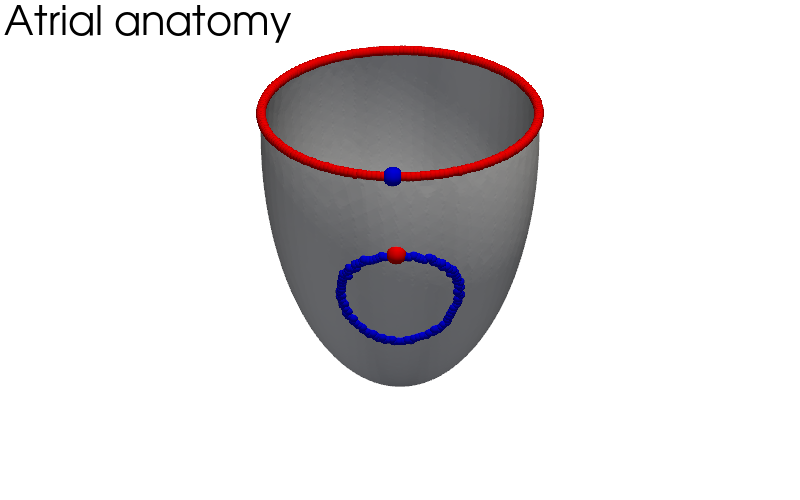

In [ ]:
from pathlib import Path
import numpy as np
import pyvista as pv
from scipy.spatial import KDTree
import finitewave_tools.visualization as fwv


def build_scar(points, scar_idx, radius=5.0):
    scar_point = points[scar_idx]
    distances = np.linalg.norm(points - scar_point, axis=1)
    return np.flatnonzero(distances < radius)


def closest_pair(points, inds_a, inds_b):
    points_a = points[inds_a]
    points_b = points[inds_b]
    tree = KDTree(points_b)
    distances, indices_b = tree.query(points_a, k=1)

    index_a = np.argmin(distances)
    index_b = indices_b[index_a]

    return inds_a[index_a], inds_b[index_b]


path = Path(".")

points = np.load(path / "data/lv_surface_points.npy")
elems = np.load(path / "data/lv_surface_elements.npy")
points = points[:, [2, 1, 0]]

z_mid = 3/4 * np.mean(points[:, 2])
scar_ind = np.argmax(np.where(points[:, 2] < z_mid, 
                              points[:, 1] + points[:, 0],
                              -np.inf))
scar_area_inds = build_scar(points, scar_ind, radius=8.0)

camera_position = "iso"

poly = fwv.PyVistaSurfaceGrid(points, elems)
poly["point_ids"] = np.arange(points.shape[0])
poly_without_scar, ind_map = poly.remove_points(scar_area_inds)

edges = poly_without_scar.extract_feature_edges(
    boundary_edges=True, feature_edges=False, manifold_edges=False,
    non_manifold_edges=False)
lines = edges.connectivity()
groups = lines.cell_data["RegionId"]

grouped_lines = [
    lines.extract_cells(groups == i)
    for i in np.unique(groups)
]
grouped_lines.sort(key=lambda x: x.n_points, reverse=True)

mv_boundary_inds = grouped_lines[0]["point_ids"]
scar_boundary_inds = grouped_lines[1]["point_ids"]

mv_closest_ind, scar_closest_ind = closest_pair(points, mv_boundary_inds, scar_boundary_inds)

pv.set_jupyter_backend("static")
pl = pv.Plotter(window_size=(800, 500))
pl.set_background("white")
pl.add_text("Atrial anatomy", position="upper_left", font_size=16, color="black")
# pl.add_mesh(poly, color="white", opacity=1., show_edges=True)
pl.add_mesh(poly, color="white", opacity=1., show_edges=False)
pl.add_points(points[mv_boundary_inds], color="red", point_size=10,
              render_points_as_spheres=True)
pl.add_points(points[scar_boundary_inds], color="blue", point_size=10,
              render_points_as_spheres=True)
pl.add_points(points[mv_closest_ind], color="blue", point_size=20,
              render_points_as_spheres=True)
pl.add_points(points[scar_closest_ind], color="red", point_size=20,
              render_points_as_spheres=True)
pl.camera_position = camera_position
pl.show()


## 2. Geodesic phase fields

### 2.1. Distance and circumferential directions

For each source, diffuse a heat impulse and normalize its negative surface gradient:

$$
(M+tK)q=b,\qquad
\mathbf e_r=-\frac{\nabla_S q}{|\nabla_S q|}.
$$

A Poisson reconstruction gives the approximate geodesic distance $d$, fixed to zero at the source. Rotating $\mathbf e_r$ within the tangent plane gives the circumferential direction $\mathbf e_\theta$. Opposite surface-normal orientations give opposite senses of rotation for the two fields.

### 2.2. Angular scale from distance bands

For a distance band $B_i=\{d_i\leq d<d_{i+1}\}$, estimate its mean isochrone length and angular scale using

$$
\overline P_i\approx\frac{1}{d_{i+1}-d_i}
\sum_{e\in B_i} a_e|\nabla_S d|_e,
\qquad h_i=\frac{\overline P_i}{2\pi}.
$$

Here $a_e$ is triangle area; triangles are assigned to bands by their mean nodal distance. Interpolation gives an elementwise scale $h$ with units of length. This is a contour-average estimate, rather than a local Jacobi scale.

### 2.3. Magnetic phase and combination

The vector potential $\mathbf A=\mathbf e_\theta/h$ guides a complex field through the energy

$$
E(\psi)=\int_S|\nabla_S\psi-i\mathbf A\psi|^2\,dS.
$$

The lowest generalized eigenmode, $L_A\psi=\lambda M\psi$, supplies the reference-aligned phase

$$
\theta=\arg\!\left(\psi e^{-i\arg\psi_{\mathrm{ref}}}\right).
$$

At each node, the composite field selects the phase with larger absolute value from the two aligned fields. This is a heuristic combination and can introduce seams. Phase is unreliable where the eigenmode amplitude approaches zero; the jump between $-\pi$ and $\pi$ is the usual angular wrap.

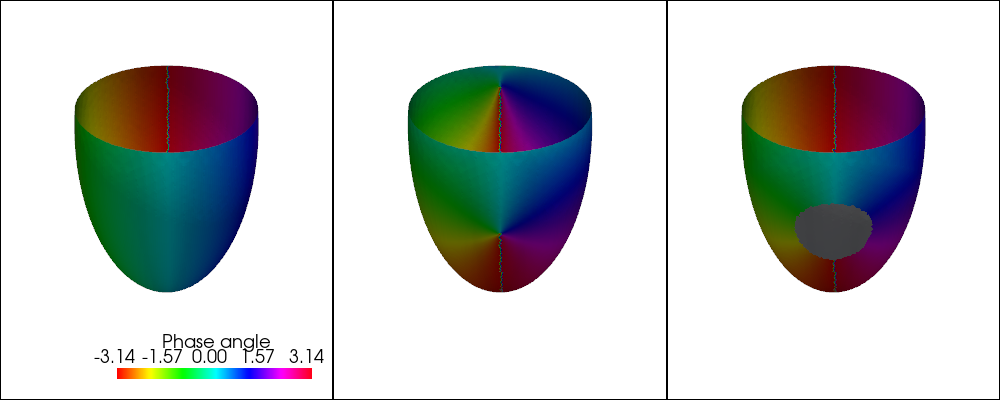

In [2]:
import numpy as np
import finitewave as fw
import finitewave_tools.geometry as geometry


tissue = fw.CardiacTissueElements(points, elems, elem_type=fw.ElementType.TRIANGLE)

spatial_discretization = fw.FiniteElementDiscretization()
K, M = spatial_discretization.compute_weights(tissue)

areas = spatial_discretization.compute_element_sizes(points, elems)
G = spatial_discretization.build_gradient_operator(points, elems, as_sparse=False)

pos_normals = poly.cell_normals
neg_normals = - pos_normals

geod_dist_0, geod_phase_0 = geometry.geodesic_coords(K, M, G, elems, areas,
                                                     pos_normals,
                                                     mv_boundary_inds,
                                                     scar_closest_ind)
geod_dist_1, geod_phase_1 = geometry.geodesic_coords(K, M, G, elems, areas,
                                                     neg_normals, 
                                                     scar_ind,
                                                     mv_closest_ind)
geod_phase = np.where(np.abs(geod_phase_0) > np.abs(geod_phase_1), 
                      geod_phase_0, geod_phase_1)
geod_phase[scar_area_inds] = np.nan  # Mask out the scar area.

pv.set_jupyter_backend("static")
pl = pv.Plotter(shape=(1, 3), window_size=(1000, 400))

for i, phase in enumerate([geod_phase_0, geod_phase_1, geod_phase]):
    pl.subplot(0, i)
    pl.add_mesh(poly, scalars=phase, cmap="hsv", clim=(-np.pi, np.pi), show_edges=False,
                scalar_bar_args={"title": "Phase angle"},
                copy_mesh=True)
    pl.camera_position = camera_position
pl.link_views()
pl.show()

## 3. Single-cell pacing

Repeated stimulation brings the Aliev–Panfilov state toward a paced response. Two successive pacing intervals prepare the recovery variable as well as the excitation variable. The recorded trace shows the final part of this preparation.

The model uses normalized excitation and model time units; its excitation variable is not a voltage measured directly in millivolts.

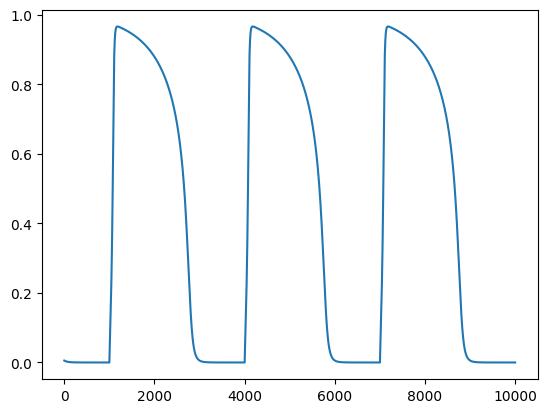

In [3]:
import finitewave as fw
import numpy as np
import matplotlib.pyplot as plt


stim_prepacing = fw.StimSingleCell(dt=0.01)
stim_prepacing.add_stim(n_beats=100, cycle_length=60, duration=1, curr_value=0.5)
stim_prepacing.add_stim(n_beats=100, cycle_length=30, duration=1, curr_value=0.5)

cardiac_model = fw.AlievPanfilov()
cardiac_model.prepacing(stim_prepacing, history=True)

plt.plot(cardiac_model.u_pacing[-10000:])
plt.show()

## 4. Map phase to cardiac state

A traveling wave in a short tissue strip supplies a reference trajectory $\mathbf y_*(\tau)$ containing all model state variables. The spatial phase assigns a trajectory time at each surface point:

$$
\tau(\mathbf x)\approx T\frac{\pi-\theta(\mathbf x)}{2\pi},
\qquad
\mathbf y(\mathbf x,0)=\mathbf y_*(\tau(\mathbf x)).
$$

The mapping uses discrete trajectory samples, with $T$ denoting the sampled time interval. Assigning the full state preserves the relationship between excitation and recovery along the trajectory. Continuity across the angular wrap depends on agreement between the trajectory endpoints.

Running AlievPanfilov on (50, 1) Grid:   0%|          | 0/3000 [00:00<?, ?it/s]

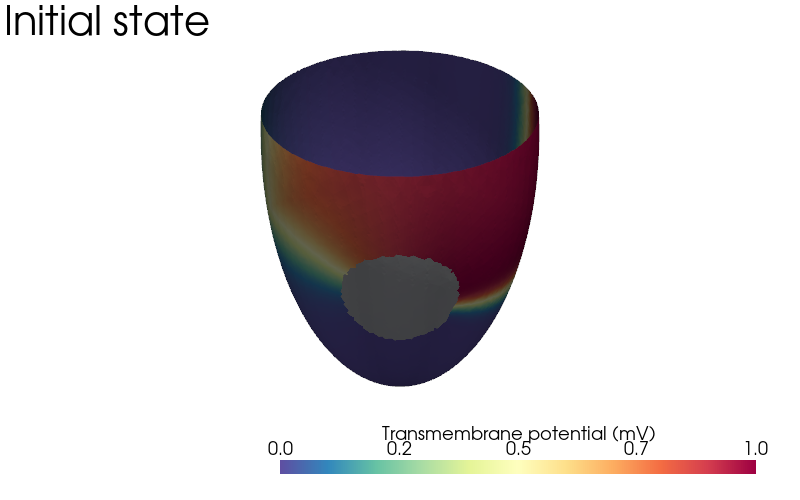

In [4]:

import numpy as np
import pyvista as pv

import finitewave as fw
import numpy as np


stim_prepacing = fw.StimSingleCell(dt=0.01)
stim_prepacing.add_stim(n_beats=100, cycle_length=60, duration=1, curr_value=0.5)
stim_prepacing.add_stim(n_beats=100, cycle_length=30, duration=1, curr_value=0.5)

cardiac_model = fw.AlievPanfilov()
cardiac_model.prepacing(stim_prepacing)

# create a tissue of size 50x1 to collect the state variables.
n, m = 50, 1
tissue = fw.CardiacTissue([n, m], dr=0.25)

# set up stimulation parameters:
stim_sequence = fw.StimSequence()
stim_sequence.add_stim(fw.StimCurrentCoord(time=0, curr_value=0.5, duration=2,
                                           x_min=0, x_max=1, y_min=0, y_max=m))

state_tracker = fw.MultiVariableTracker(node_inds=[(n//2, m//2)], step=10, start_time=0)
tracker_sequence = fw.TrackerSequence()
tracker_sequence.add_tracker(state_tracker)

# create model object and set up parameters:
simulation = fw.CardiacSimulation(dt=0.01, t_max=30, backend="numba")

simulation.cardiac_model = cardiac_model
simulation.cardiac_tissue = tissue
simulation.stim_sequence = stim_sequence
simulation.tracker_sequence = tracker_sequence

# run the model:
simulation.run()

state_vars = {}
n_levels = len(state_tracker.tracking_times)
state_map = n_levels - np.digitize(geod_phase, bins=np.linspace(-np.pi, np.pi, n_levels))
for var_name in cardiac_model.state_vars:
    tracked_values = state_tracker.output[var_name]
    var_array = tracked_values[state_map]
    var_array[scar_area_inds] = np.nan  # Mask out the scar area.
    state_vars[var_name] = var_array


pv.set_jupyter_backend("static")
pl = pv.Plotter(window_size=(800, 500))
pl.set_background("white")
pl.add_text("Initial state", position="upper_left", font_size=16, color="black")
pl.add_mesh(poly, scalars=state_vars["u"], cmap="Spectral_r", opacity=1,
            scalar_bar_args={"title": "Transmembrane potential (mV)",
                             "color": "black", "n_labels": 5, "fmt": "%.1f"})
pl.camera_position = camera_position
pl.show()


## 5. Propagate the initialized wave

The initialized state evolves on the triangular surface under reaction–diffusion dynamics:

$$
\frac{\partial u}{\partial t}
=\nabla_S\cdot(D\nabla_Su)+f(u,v),
\qquad
\frac{\partial v}{\partial t}=g(u,v).
$$

The scar region is assigned a fibrotic tissue label. The resulting propagation shows whether the prescribed excitation pattern persists, reorganizes, or terminates; phase initialization alone does not guarantee sustained reentry.

Running AlievPanfilov on Triangle Elements:   0%|          | 0/20000 [00:00<?, ?it/s]

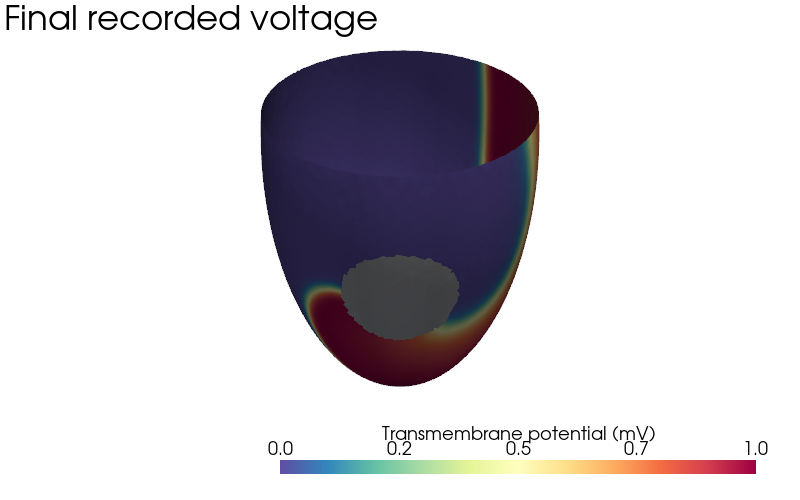

In [5]:
cardiac_model = fw.AlievPanfilov()
cardiac_model.prepacing(stim_prepacing)
cardiac_model.set_variables(state_vars)

frame_tracker = fw.FrameTracker(aggregate=True, step=100, start_time=0)

# create model object and set up parameters:
simulation = fw.CardiacSimulation(dt=0.01, t_max=200, backend="jax")
simulation.cardiac_tissue = fw.CardiacTissue(coords=points, elems=elems,
                                             elem_type=fw.ElementType.TRIANGLE)
simulation.cardiac_tissue.mesh[scar_area_inds] = 2.
simulation.cardiac_model = cardiac_model
simulation.time_integration = fw.BackwardEulerTimeIntegration(atol=1e-6)
simulation.tracker_sequence = fw.TrackerSequence()
simulation.tracker_sequence.add_tracker(frame_tracker)

# run the model:
simulation.run()

u = cardiac_model.u

pv.set_jupyter_backend("static")
pl = pv.Plotter(window_size=(800, 500))
pl.set_background("white")
pl.add_text("Final recorded voltage", position="upper_left", font_size=16, color="black")
pl.add_mesh(poly, scalars=u, cmap="Spectral_r", opacity=1,
            scalar_bar_args={"title": "Transmembrane potential (mV)",
                             "color": "black", "n_labels": 5, "fmt": "%.1f"})
pl.camera_position = camera_position
pl.show()

## 6. Visualize the wave evolution

Successive surface fields show the motion of excitation around the opening and scar. A fixed color range of $0\leq u\leq1$ allows comparison across time. The animation displays normalized Aliev–Panfilov excitation.

In [6]:
from pathlib import Path
import numpy as np
import finitewave_tools.visualization as fwv
import finitewave_tools.animation as fwa

# get the resulting potential at the element centers:
sample_times = frame_tracker.tracking_times
frames = frame_tracker.frames[:len(sample_times)]

animation_name = "phase_initialization"

scalar_name = "Membrane potential (mV)"

animation_grid = fwv.PyVistaSurfaceGrid(points, elems)

renderer = fwa.Frame3DRenderer()
renderer.set_frames(frames=frames)
renderer.configure_grid(animation_grid, window_size=(1920, 1080))

output_dir = Path("./output")
output_dir.mkdir(parents=True, exist_ok=True)

animation = fwa.AnimationBuilder()
animation.frame_renderer = renderer
animation.write(
    path=output_dir,
    animation_name=animation_name,
    fps=24,
    prog_bar=True,
    scalar_name=scalar_name,
    cmap="Spectral_r",
    nan_color="white",
    clim=(0, 1),
    camera_position=camera_position,
)

video_path = output_dir / f"{animation_name}.mp4"


Building animation:   0%|          | 0/201 [00:00<?, ?it/s]

In [7]:
from IPython.display import Video, display

display(Video(str(video_path), embed=True, width=800))